# CarePath-AI | Phase 01 - System Architecture & Foundations
**Version 0.1.1 · Schema version 1 · Research prototype**

This executable notebook establishes the database, configuration, reusable services, synthetic patient journey and automated verification for future phases. All records are fictional. Risk values are placeholders, not trained model outputs. No external services are called. Run cells in order or choose **Run All**. Existing databases are not reset.

### Phase 1 objectives
1. Create an extensible relational database with integrity constraints.
2. Establish role-checked, audited intervention workflows with approval and consent gates.
3. Demonstrate the synthetic patient journey and validate the implementation.

The packaged architecture and ERD are in `documentation/`. A standalone notebook bootstraps source files if the project is absent.

In [ ]:
import sys
import json
import sqlite3
import logging
import subprocess
import platform
import os

from contextlib import closing
from IPython.display import display, Markdown
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p/'carepath/schema.sql').is_file() and (p/'config/settings.json').is_file()), cwd/'CarePath_AI_Phase1')
ROOT.mkdir(parents=True, exist_ok=True)
print("Project:", ROOT.name)
print("Python:", platform.python_version(), "| SQLite:", sqlite3.sqlite_version)
with closing(sqlite3.connect(':memory:')) as probe:
    assert probe.execute("SELECT json_valid('{}')").fetchone()[0] == 1, 'SQLite JSON support required' 

Project: CarePath_AI_Phase1_v0.1.1
Python: 3.13.5 | SQLite: 3.46.1


## 1. Portable project bootstrap
The following three cells carry the same versioned source as the packaged project. They write only missing files so the notebook can run independently. Existing project files are used as-is; the notebook never overwrites customised code. The package is the preferred working copy for subsequent phases.

In [2]:
# Embedded source files: generated from the same release as the ZIP.
sources = {
    'carepath/__init__.py': '"""CarePath-AI research prototype foundation."""\n__version__ = \'0.1.1\'\n',
    'config/settings.json': '{\n  "project": "CarePath-AI",\n  "version": "0.1.1",\n  "mode": "simulation",\n  "database": "database/carepath_ai.db",\n  "timezone": "UTC",\n  "allow_external_calls": false,\n  "allow_real_patient_data": false\n}\n',
    'carepath/schema.sql': "PRAGMA foreign_keys = ON;\nBEGIN;\nCREATE TABLE IF NOT EXISTS schema_version(version INTEGER PRIMARY KEY CHECK(version=1), applied_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nINSERT OR IGNORE INTO schema_version(version) VALUES(1);\nCREATE TABLE IF NOT EXISTS staff(staff_id TEXT PRIMARY KEY, display_name TEXT NOT NULL, role TEXT NOT NULL CHECK(role IN ('admin','reviewer','coordinator','analyst')), active INTEGER NOT NULL DEFAULT 1 CHECK(active IN (0,1)));\nCREATE TABLE IF NOT EXISTS patients(patient_id TEXT PRIMARY KEY, age_band TEXT NOT NULL CHECK(age_band IN ('18-29','30-44','45-59','60-74','75+','unknown')), contact_ref TEXT UNIQUE, sms_opt_in INTEGER NOT NULL DEFAULT 0 CHECK(sms_opt_in IN (0,1)), is_synthetic INTEGER NOT NULL DEFAULT 1 CHECK(is_synthetic=1), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP, CHECK(sms_opt_in=0 OR contact_ref IS NOT NULL));\nCREATE TABLE IF NOT EXISTS appointments(appointment_id TEXT PRIMARY KEY, patient_id TEXT NOT NULL REFERENCES patients(patient_id), scheduled_at TEXT NOT NULL CHECK(datetime(scheduled_at) IS NOT NULL), department TEXT NOT NULL, appointment_type TEXT NOT NULL, status TEXT NOT NULL DEFAULT 'scheduled' CHECK(status IN ('scheduled','attended','no_show','cancelled','rescheduled')), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nCREATE TABLE IF NOT EXISTS surveys(survey_id TEXT PRIMARY KEY, appointment_id TEXT NOT NULL REFERENCES appointments(appointment_id), recorded_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP, attendance_confidence INTEGER CHECK(attendance_confidence BETWEEN 0 AND 10), transport_difficulty INTEGER CHECK(transport_difficulty IN (0,1)), financial_difficulty INTEGER CHECK(financial_difficulty IN (0,1)), accessibility_need INTEGER CHECK(accessibility_need IN (0,1)), timing_conflict INTEGER CHECK(timing_conflict IN (0,1)), language_support INTEGER CHECK(language_support IN (0,1)), caring_responsibility INTEGER CHECK(caring_responsibility IN (0,1)), support_consent INTEGER NOT NULL DEFAULT 0 CHECK(support_consent IN (0,1)));\nCREATE TABLE IF NOT EXISTS model_registry(model_id TEXT PRIMARY KEY, model_kind TEXT NOT NULL CHECK(model_kind IN ('predictive','causal','nlp','placeholder')), version TEXT NOT NULL, artifact_path TEXT, validation_status TEXT NOT NULL DEFAULT 'unvalidated' CHECK(validation_status IN ('unvalidated','synthetic_validated','external_validated')), UNIQUE(model_kind,version));\nCREATE TABLE IF NOT EXISTS predictions(prediction_id TEXT PRIMARY KEY, appointment_id TEXT NOT NULL REFERENCES appointments(appointment_id), model_id TEXT NOT NULL REFERENCES model_registry(model_id), predicted_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP, no_show_probability REAL NOT NULL CHECK(no_show_probability BETWEEN 0 AND 1), explanation_json TEXT CHECK(explanation_json IS NULL OR json_valid(explanation_json)), is_simulated INTEGER NOT NULL DEFAULT 1 CHECK(is_simulated=1));\nCREATE TABLE IF NOT EXISTS barriers(barrier_id TEXT PRIMARY KEY, appointment_id TEXT NOT NULL REFERENCES appointments(appointment_id), category TEXT NOT NULL CHECK(category IN ('transport','financial','accessibility','timing','language','caring','anxiety','other')), source TEXT NOT NULL CHECK(source IN ('survey','chatbot','staff')), recorded_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP, confirmed INTEGER NOT NULL DEFAULT 0 CHECK(confirmed IN (0,1)));\nCREATE TABLE IF NOT EXISTS interventions(intervention_id TEXT PRIMARY KEY, appointment_id TEXT NOT NULL REFERENCES appointments(appointment_id), kind TEXT NOT NULL CHECK(kind IN ('transport','reschedule','reminder','interpreter','accessibility','financial_support','staff_review')), rationale TEXT NOT NULL, estimated_benefit REAL CHECK(estimated_benefit BETWEEN -1 AND 1), evidence_status TEXT NOT NULL DEFAULT 'not_estimated' CHECK(evidence_status IN ('not_estimated','synthetic_estimate')), status TEXT NOT NULL DEFAULT 'proposed' CHECK(status IN ('proposed','approved','rejected','in_progress','completed','cancelled')), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP, CHECK((estimated_benefit IS NULL AND evidence_status='not_estimated') OR (estimated_benefit IS NOT NULL AND evidence_status='synthetic_estimate')));\nCREATE TABLE IF NOT EXISTS intervention_decisions(decision_id TEXT PRIMARY KEY, intervention_id TEXT NOT NULL UNIQUE REFERENCES interventions(intervention_id), staff_id TEXT NOT NULL REFERENCES staff(staff_id), decision TEXT NOT NULL CHECK(decision IN ('approve','reject')), reason TEXT NOT NULL CHECK(length(trim(reason))>0), decided_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nCREATE TABLE IF NOT EXISTS communications(message_id TEXT PRIMARY KEY, appointment_id TEXT NOT NULL REFERENCES appointments(appointment_id), intervention_id TEXT REFERENCES interventions(intervention_id), channel TEXT NOT NULL CHECK(channel='sms'), template_key TEXT NOT NULL, dedupe_key TEXT NOT NULL UNIQUE, status TEXT NOT NULL DEFAULT 'simulated' CHECK(status IN ('simulated','failed')), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nCREATE TABLE IF NOT EXISTS transport_referrals(referral_id TEXT PRIMARY KEY, intervention_id TEXT NOT NULL UNIQUE REFERENCES interventions(intervention_id), eligibility_status TEXT NOT NULL CHECK(eligibility_status IN ('demo_eligible','demo_ineligible','review_required')), mobility_notes TEXT, status TEXT NOT NULL DEFAULT 'pending' CHECK(status IN ('pending','submitted','cancelled','completed')), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nCREATE TABLE IF NOT EXISTS transport_bookings(booking_id TEXT PRIMARY KEY, referral_id TEXT NOT NULL UNIQUE REFERENCES transport_referrals(referral_id), provider TEXT NOT NULL CHECK(provider='SIMULATED_PROVIDER'), pickup_at TEXT NOT NULL CHECK(datetime(pickup_at) IS NOT NULL), status TEXT NOT NULL DEFAULT 'simulated' CHECK(status IN ('simulated','cancelled','completed')), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nCREATE TABLE IF NOT EXISTS audit_events(event_id INTEGER PRIMARY KEY AUTOINCREMENT, actor_id TEXT REFERENCES staff(staff_id), action TEXT NOT NULL, entity_type TEXT NOT NULL, entity_id TEXT NOT NULL, details_json TEXT NOT NULL DEFAULT '{}' CHECK(json_valid(details_json)), created_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP);\nCREATE INDEX IF NOT EXISTS idx_appointments_patient ON appointments(patient_id,scheduled_at);\nCREATE INDEX IF NOT EXISTS idx_appointments_status ON appointments(status,scheduled_at);\nCREATE INDEX IF NOT EXISTS idx_surveys_appointment ON surveys(appointment_id,recorded_at);\nCREATE INDEX IF NOT EXISTS idx_predictions_appointment ON predictions(appointment_id,predicted_at);\nCREATE INDEX IF NOT EXISTS idx_barriers_appointment ON barriers(appointment_id);\nCREATE INDEX IF NOT EXISTS idx_interventions_appointment ON interventions(appointment_id,status);\nCREATE INDEX IF NOT EXISTS idx_messages_appointment ON communications(appointment_id);\nCREATE INDEX IF NOT EXISTS idx_audit_entity ON audit_events(entity_type,entity_id);\nCREATE TRIGGER IF NOT EXISTS audit_no_update BEFORE UPDATE ON audit_events BEGIN SELECT RAISE(ABORT,'audit events are append-only'); END;\nCREATE TRIGGER IF NOT EXISTS audit_no_delete BEFORE DELETE ON audit_events BEGIN SELECT RAISE(ABORT,'audit events are append-only'); END;\nCREATE TRIGGER IF NOT EXISTS decision_guard BEFORE INSERT ON intervention_decisions BEGIN\n SELECT CASE WHEN NOT EXISTS(SELECT 1 FROM staff WHERE staff_id=NEW.staff_id AND active=1 AND role IN ('admin','reviewer')) THEN RAISE(ABORT,'active reviewer required') END;\n SELECT CASE WHEN NOT EXISTS(SELECT 1 FROM interventions WHERE intervention_id=NEW.intervention_id AND status='proposed') THEN RAISE(ABORT,'intervention must be proposed') END;\nEND;\nCREATE TRIGGER IF NOT EXISTS decision_no_update BEFORE UPDATE ON intervention_decisions BEGIN SELECT RAISE(ABORT,'decisions immutable'); END;\nCREATE TRIGGER IF NOT EXISTS decision_no_delete BEFORE DELETE ON intervention_decisions BEGIN SELECT RAISE(ABORT,'decisions immutable'); END;\nCREATE TRIGGER IF NOT EXISTS intervention_insert_guard BEFORE INSERT ON interventions WHEN NEW.status<>'proposed' BEGIN SELECT RAISE(ABORT,'new intervention must be proposed'); END;\nCREATE TRIGGER IF NOT EXISTS intervention_identity_guard BEFORE UPDATE OF appointment_id,kind ON interventions WHEN NEW.appointment_id<>OLD.appointment_id OR NEW.kind<>OLD.kind BEGIN SELECT RAISE(ABORT,'intervention identity immutable'); END;\nCREATE TRIGGER IF NOT EXISTS intervention_transition BEFORE UPDATE OF status ON interventions WHEN NEW.status<>OLD.status BEGIN\n SELECT CASE WHEN NOT ((OLD.status='proposed' AND NEW.status IN ('approved','rejected','cancelled')) OR (OLD.status='approved' AND NEW.status IN ('in_progress','cancelled')) OR (OLD.status='in_progress' AND NEW.status IN ('completed','cancelled'))) THEN RAISE(ABORT,'invalid intervention transition') END;\n SELECT CASE WHEN NEW.status IN ('approved','in_progress','completed') AND NOT EXISTS(SELECT 1 FROM intervention_decisions WHERE intervention_id=NEW.intervention_id AND decision='approve') THEN RAISE(ABORT,'approval required') END;\n SELECT CASE WHEN NEW.status='rejected' AND NOT EXISTS(SELECT 1 FROM intervention_decisions WHERE intervention_id=NEW.intervention_id AND decision='reject') THEN RAISE(ABORT,'rejection decision required') END;\nEND;\nCREATE TRIGGER IF NOT EXISTS decision_apply AFTER INSERT ON intervention_decisions BEGIN UPDATE interventions SET status=CASE NEW.decision WHEN 'approve' THEN 'approved' ELSE 'rejected' END WHERE intervention_id=NEW.intervention_id; END;\nCREATE TRIGGER IF NOT EXISTS sms_guard BEFORE INSERT ON communications BEGIN\n SELECT CASE WHEN NOT EXISTS(SELECT 1 FROM appointments a JOIN patients p ON p.patient_id=a.patient_id WHERE a.appointment_id=NEW.appointment_id AND a.status='scheduled' AND p.sms_opt_in=1 AND p.contact_ref IS NOT NULL) THEN RAISE(ABORT,'scheduled appointment and SMS opt-in required') END;\n SELECT CASE WHEN NEW.intervention_id IS NOT NULL AND NOT EXISTS(SELECT 1 FROM interventions i JOIN intervention_decisions d ON d.intervention_id=i.intervention_id WHERE i.intervention_id=NEW.intervention_id AND i.appointment_id=NEW.appointment_id AND d.decision='approve' AND i.status IN ('approved','in_progress','completed')) THEN RAISE(ABORT,'matching approved intervention required') END;\nEND;\nCREATE TRIGGER IF NOT EXISTS sms_no_update BEFORE UPDATE ON communications BEGIN SELECT RAISE(ABORT,'communication records immutable'); END;\nCREATE TRIGGER IF NOT EXISTS referral_guard BEFORE INSERT ON transport_referrals BEGIN\n SELECT CASE WHEN NEW.status<>'pending' THEN RAISE(ABORT,'new referral must be pending') END;\n SELECT CASE WHEN NOT EXISTS(SELECT 1 FROM interventions i JOIN intervention_decisions d ON d.intervention_id=i.intervention_id JOIN appointments a ON a.appointment_id=i.appointment_id WHERE i.intervention_id=NEW.intervention_id AND i.kind='transport' AND i.status IN ('approved','in_progress') AND d.decision='approve' AND a.status='scheduled' AND EXISTS(SELECT 1 FROM surveys s WHERE s.appointment_id=a.appointment_id AND s.support_consent=1 AND s.rowid=(SELECT s2.rowid FROM surveys s2 WHERE s2.appointment_id=a.appointment_id ORDER BY s2.recorded_at DESC,s2.rowid DESC LIMIT 1))) THEN RAISE(ABORT,'approved transport intervention and latest support consent required') END;\nEND;\nCREATE TRIGGER IF NOT EXISTS referral_identity_guard BEFORE UPDATE OF intervention_id ON transport_referrals WHEN NEW.intervention_id<>OLD.intervention_id BEGIN SELECT RAISE(ABORT,'referral identity immutable'); END;\nCREATE TRIGGER IF NOT EXISTS booking_guard BEFORE INSERT ON transport_bookings BEGIN\n SELECT CASE WHEN NEW.status<>'simulated' THEN RAISE(ABORT,'new booking must be simulated') END;\n SELECT CASE WHEN NOT EXISTS(SELECT 1 FROM transport_referrals r JOIN interventions i ON i.intervention_id=r.intervention_id JOIN intervention_decisions d ON d.intervention_id=i.intervention_id JOIN appointments a ON a.appointment_id=i.appointment_id WHERE r.referral_id=NEW.referral_id AND r.eligibility_status='demo_eligible' AND r.status='pending' AND i.status IN ('approved','in_progress') AND d.decision='approve' AND a.status='scheduled' AND datetime(NEW.pickup_at)<datetime(a.scheduled_at) AND EXISTS(SELECT 1 FROM surveys s WHERE s.appointment_id=a.appointment_id AND s.support_consent=1 AND s.rowid=(SELECT s2.rowid FROM surveys s2 WHERE s2.appointment_id=a.appointment_id ORDER BY s2.recorded_at DESC,s2.rowid DESC LIMIT 1))) THEN RAISE(ABORT,'eligible pending referral, approval, current consent and pickup before appointment required') END;\nEND;\nCREATE TRIGGER IF NOT EXISTS booking_identity_guard BEFORE UPDATE OF referral_id,provider,pickup_at ON transport_bookings WHEN NEW.referral_id<>OLD.referral_id OR NEW.provider<>OLD.provider OR NEW.pickup_at<>OLD.pickup_at BEGIN SELECT RAISE(ABORT,'booking identity immutable'); END;\nCREATE VIEW IF NOT EXISTS appointment_overview AS SELECT a.appointment_id,a.patient_id,a.scheduled_at,a.department,a.status,p.sms_opt_in,(SELECT no_show_probability FROM predictions pr WHERE pr.appointment_id=a.appointment_id ORDER BY predicted_at DESC,rowid DESC LIMIT 1) AS latest_risk FROM appointments a JOIN patients p ON p.patient_id=a.patient_id;\nCOMMIT;\n",
}
for relative, source in sources.items():
    target = ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.exists():
        target.write_text(source, encoding="utf-8")
print("Source files available:", len(sources))

Source files available: 3


In [3]:
# Embedded source files: generated from the same release as the ZIP.
sources = {
    'carepath/foundation.py': '"""SQLite foundation. All data and external actions are simulated.\nStaff identifiers are demo role assertions, NOT authenticated identities.\nUse the service methods rather than direct SQL for audited write operations.\n"""\nimport json\nimport logging\nimport sqlite3\nfrom contextlib import contextmanager\nfrom pathlib import Path\n\nROOT = Path(__file__).resolve().parents[1]\nLOG = logging.getLogger(\'carepath\')\n\n\ndef load_settings(root=ROOT):\n    settings = json.loads((Path(root) / \'config/settings.json\').read_text(encoding=\'utf-8\'))\n    if (settings[\'mode\'] != \'simulation\' or settings[\'allow_external_calls\'] is not False\n            or settings[\'allow_real_patient_data\'] is not False or settings[\'timezone\'] != \'UTC\'):\n        raise ValueError(\'Phase 1 supports synthetic, offline UTC simulation only\')\n    path = Path(settings[\'database\'])\n    if path.is_absolute() or \'..\' in path.parts:\n        raise ValueError(\'Database must be inside project\')\n    return settings\n\n\n@contextmanager\ndef connect(path):\n    conn = sqlite3.connect(path, timeout=10)\n    conn.row_factory = sqlite3.Row\n    conn.execute(\'PRAGMA foreign_keys=ON\')\n    conn.execute(\'PRAGMA busy_timeout=10000\')\n    try:\n        with conn:\n            yield conn\n    except Exception as exc:\n        LOG.warning(\'Database transaction rolled back: %s\', type(exc).__name__)\n        raise\n    finally:\n        conn.close()\n\n\ndef initialize(path):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with connect(path) as conn:\n        # Fail closed when opening a database belonging to an unknown schema.\n        exists = conn.execute("SELECT 1 FROM sqlite_master WHERE type=\'table\' AND name=\'schema_version\'").fetchone()\n        if exists and [r[0] for r in conn.execute(\'SELECT version FROM schema_version\')] != [1]:\n            raise ValueError(\'Unsupported schema version\')\n        conn.executescript((ROOT / \'carepath/schema.sql\').read_text(encoding=\'utf-8\'))\n    return path\n\n\ndef authorize(conn, actor, roles):\n    row = conn.execute(\'SELECT role, active FROM staff WHERE staff_id=?\', (actor,)).fetchone()\n    if not row or not row[\'active\'] or row[\'role\'] not in roles:\n        raise PermissionError(\'Role not authorised for this operation\')\n\n\ndef audit(conn, actor, action, entity, entity_id, details=None):\n    conn.execute(\'INSERT INTO audit_events(actor_id,action,entity_type,entity_id,details_json) VALUES(?,?,?,?,?)\',\n                 (actor, action, entity, entity_id, json.dumps(details or {}, sort_keys=True)))\n\n\ndef propose(conn, actor, intervention_id, appointment_id, kind, rationale):\n    authorize(conn, actor, {\'admin\',\'reviewer\',\'coordinator\'})\n    if not rationale.strip():\n        raise ValueError(\'Rationale required\')\n    conn.execute(\'INSERT INTO interventions(intervention_id,appointment_id,kind,rationale) VALUES(?,?,?,?)\',\n                 (intervention_id, appointment_id, kind, rationale))\n    audit(conn, actor, \'proposed\', \'intervention\', intervention_id, {\'kind\':kind})\n\n\ndef decide(conn, actor, decision_id, intervention_id, decision, reason):\n    authorize(conn, actor, {\'admin\',\'reviewer\'})\n    conn.execute(\'INSERT INTO intervention_decisions(decision_id,intervention_id,staff_id,decision,reason) VALUES(?,?,?,?,?)\',\n                 (decision_id, intervention_id, actor, decision, reason))\n    audit(conn, actor, decision, \'intervention\', intervention_id)\n\n\ndef simulate_sms(conn, actor, message_id, appointment_id, template_key, dedupe_key, intervention_id=None):\n    authorize(conn, actor, {\'admin\',\'reviewer\',\'coordinator\'})\n    existing = conn.execute(\'SELECT * FROM communications WHERE dedupe_key=?\', (dedupe_key,)).fetchone()\n    if existing:\n        if (existing[\'appointment_id\'],existing[\'template_key\'],existing[\'intervention_id\']) != (appointment_id,template_key,intervention_id):\n            raise ValueError(\'Deduplication key conflict\')\n        return existing[\'message_id\']\n    if template_key not in {\'standard_reminder\',\'support_invitation\',\'support_confirmation\',\'transport_confirmation\'}:\n        raise ValueError(\'Unknown template\')\n    if template_key in {\'support_confirmation\',\'transport_confirmation\'} and intervention_id is None:\n        raise ValueError(\'Confirmation requires an approved intervention\')\n    if template_key == \'transport_confirmation\' and not conn.execute(\'\'\'SELECT 1 FROM transport_bookings b JOIN transport_referrals r ON r.referral_id=b.referral_id WHERE r.intervention_id=? AND b.status=\'simulated\' AND r.status=\'submitted\' \'\'\',(intervention_id,)).fetchone():\n        raise ValueError(\'Transport confirmation requires simulated booking\')\n    conn.execute(\'INSERT INTO communications(message_id,appointment_id,intervention_id,channel,template_key,dedupe_key) VALUES(?,?,?,\\\'sms\\\',?,?)\',\n                 (message_id, appointment_id, intervention_id, template_key, dedupe_key))\n    audit(conn, actor, \'sms_simulated\', \'communication\', message_id)\n    return message_id\n\n\ndef create_referral(conn, actor, referral_id, intervention_id, eligibility_status=\'review_required\', mobility_notes=None):\n    authorize(conn, actor, {\'admin\',\'reviewer\',\'coordinator\'})\n    conn.execute(\'INSERT INTO transport_referrals(referral_id,intervention_id,eligibility_status,mobility_notes) VALUES(?,?,?,?)\',\n                 (referral_id, intervention_id, eligibility_status, mobility_notes))\n    audit(conn, actor, \'referral_created\', \'transport_referral\', referral_id)\n\n\ndef simulate_booking(conn, actor, booking_id, referral_id, pickup_at):\n    authorize(conn, actor, {\'admin\',\'reviewer\',\'coordinator\'})\n    conn.execute("INSERT INTO transport_bookings(booking_id,referral_id,provider,pickup_at) VALUES(?,?,\'SIMULATED_PROVIDER\',?)",\n                 (booking_id, referral_id, pickup_at))\n    conn.execute("UPDATE transport_referrals SET status=\'submitted\' WHERE referral_id=?", (referral_id,))\n    conn.execute("UPDATE interventions SET status=\'in_progress\' WHERE intervention_id=(SELECT intervention_id FROM transport_referrals WHERE referral_id=?)", (referral_id,))\n    audit(conn, actor, \'booking_simulated\', \'transport_booking\', booking_id)\n\n\ndef seed_demo(conn):\n    """One deterministic synthetic fixture set; never overwrite existing data."""\n    if conn.execute("SELECT 1 FROM audit_events WHERE action=\'demo_seeded\' AND entity_id=\'phase1\'").fetchone():\n        return False\n    conn.executemany(\'INSERT INTO staff(staff_id,display_name,role) VALUES(?,?,?)\', [\n        (\'S-ADMIN\',\'Demo Admin\',\'admin\'),(\'S-REVIEW\',\'Demo Reviewer\',\'reviewer\'),\n        (\'S-COORD\',\'Demo Coordinator\',\'coordinator\'),(\'S-ANALYST\',\'Demo Analyst\',\'analyst\')])\n    conn.executemany(\'INSERT INTO patients(patient_id,age_band,contact_ref,sms_opt_in) VALUES(?,?,?,?)\',[\n        (\'P-001\',\'60-74\',\'DEMO-CONTACT-001\',1),(\'P-002\',\'30-44\',None,0),(\'P-003\',\'45-59\',\'DEMO-CONTACT-003\',1)])\n    conn.executemany(\'INSERT INTO appointments(appointment_id,patient_id,scheduled_at,department,appointment_type) VALUES(?,?,?,?,?)\',[\n        (\'A-001\',\'P-001\',\'2027-01-15T10:00:00Z\',\'Outpatients\',\'Follow-up\'),(\'A-002\',\'P-002\',\'2027-01-15T11:00:00Z\',\'Physiotherapy\',\'New\'),(\'A-003\',\'P-003\',\'2027-01-16T09:00:00Z\',\'Outpatients\',\'Follow-up\')])\n    conn.executemany(\'INSERT INTO surveys(survey_id,appointment_id,attendance_confidence,transport_difficulty,financial_difficulty,support_consent) VALUES(?,?,?,?,?,?)\',[\n        (\'SV-001\',\'A-001\',3,1,1,1),(\'SV-002\',\'A-002\',8,0,0,0),(\'SV-003\',\'A-003\',5,0,0,1)])\n    conn.execute("INSERT INTO model_registry(model_id,model_kind,version) VALUES(\'M-DEMO\',\'placeholder\',\'0.1.0\')")\n    conn.executemany(\'INSERT INTO predictions(prediction_id,appointment_id,model_id,no_show_probability) VALUES(?,?,?,?)\',[\n        (\'PR-001\',\'A-001\',\'M-DEMO\',0.82),(\'PR-002\',\'A-002\',\'M-DEMO\',0.15),(\'PR-003\',\'A-003\',\'M-DEMO\',0.61)])\n    conn.executemany(\'INSERT INTO barriers(barrier_id,appointment_id,category,source,confirmed) VALUES(?,?,?,?,?)\',[\n        (\'B-001\',\'A-001\',\'transport\',\'survey\',1),(\'B-002\',\'A-001\',\'financial\',\'survey\',1),(\'B-003\',\'A-003\',\'timing\',\'staff\',1)])\n    propose(conn,\'S-COORD\',\'I-001\',\'A-001\',\'transport\',\'Synthetic transport difficulty\')\n    simulate_sms(conn,\'S-COORD\',\'MSG-001\',\'A-001\',\'support_invitation\',\'A-001:invitation:v1\')\n    decide(conn,\'S-REVIEW\',\'D-001\',\'I-001\',\'approve\',\'Demo review only\')\n    create_referral(conn,\'S-COORD\',\'R-001\',\'I-001\',\'demo_eligible\',\'Synthetic mobility support\')\n    simulate_booking(conn,\'S-COORD\',\'BK-001\',\'R-001\',\'2027-01-15T09:00:00Z\')\n    simulate_sms(conn,\'S-COORD\',\'MSG-002\',\'A-001\',\'transport_confirmation\',\'A-001:transport:v1\',\'I-001\')\n    propose(conn,\'S-COORD\',\'I-002\',\'A-003\',\'reschedule\',\'Synthetic scheduling conflict\')\n    decide(conn,\'S-REVIEW\',\'D-002\',\'I-002\',\'reject\',\'Demo rejection; no schedule change\')\n    audit(conn,\'S-ADMIN\',\'demo_seeded\',\'fixture\',\'phase1\',{\'synthetic\':True})\n    return True\n\n\ndef integrity(conn):\n    return {\'integrity_check\':conn.execute(\'PRAGMA integrity_check\').fetchone()[0],\n            \'foreign_key_violations\':[tuple(r) for r in conn.execute(\'PRAGMA foreign_key_check\')],\n            \'schema_version\':conn.execute(\'SELECT version FROM schema_version\').fetchone()[0],\n            \'table_count\':conn.execute("SELECT count(*) FROM sqlite_master WHERE type=\'table\' AND name NOT LIKE \'sqlite_%\'").fetchone()[0]}\n\n\ndef counts(conn):\n    return {name:conn.execute(f\'SELECT count(*) FROM "{name}"\').fetchone()[0] for name in [\n        \'staff\',\'patients\',\'appointments\',\'surveys\',\'model_registry\',\'predictions\',\'barriers\',\'interventions\',\'intervention_decisions\',\'communications\',\'transport_referrals\',\'transport_bookings\',\'audit_events\']}\n',
}
for relative, source in sources.items():
    target = ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.exists():
        target.write_text(source, encoding="utf-8")
print("Source files available:", len(sources))

Source files available: 1


In [4]:
# Embedded source files: generated from the same release as the ZIP.
sources = {
    'tests/test_foundation.py': 'import sqlite3\nimport tempfile\nimport unittest\nfrom pathlib import Path\nfrom carepath.foundation import (initialize, connect, seed_demo, integrity, counts,\n    propose, decide, simulate_sms, create_referral, simulate_booking, load_settings)\n\n\nclass FoundationTests(unittest.TestCase):\n    def setUp(self):\n        self.tmp = tempfile.TemporaryDirectory()\n        self.db = initialize(Path(self.tmp.name)/\'test.db\')\n        with connect(self.db) as c:\n            seed_demo(c)\n\n    def tearDown(self):\n        self.tmp.cleanup()\n\n    def rejected(self, error, callback):\n        with self.assertRaises(error):\n            with connect(self.db) as c:\n                callback(c)\n\n    def test_integrity_and_schema(self):\n        with connect(self.db) as c:\n            self.assertEqual(integrity(c), {\'integrity_check\':\'ok\',\'foreign_key_violations\':[], \'schema_version\':1,\'table_count\':14})\n\n    def test_repeat_initialisation_and_seed(self):\n        with connect(self.db) as c: before=counts(c)\n        initialize(self.db)\n        with connect(self.db) as c:\n            self.assertFalse(seed_demo(c)); self.assertEqual(before,counts(c))\n\n    def test_valid_journey(self):\n        with connect(self.db) as c:\n            self.assertEqual(c.execute("SELECT status FROM interventions WHERE intervention_id=\'I-001\'").fetchone()[0],\'in_progress\')\n            self.assertEqual(c.execute("SELECT status FROM transport_referrals WHERE referral_id=\'R-001\'").fetchone()[0],\'submitted\')\n            self.assertEqual(c.execute("SELECT status FROM transport_bookings WHERE booking_id=\'BK-001\'").fetchone()[0],\'simulated\')\n            self.assertEqual(c.execute("SELECT status FROM interventions WHERE intervention_id=\'I-002\'").fetchone()[0],\'rejected\')\n            self.assertEqual(counts(c)[\'audit_events\'],9)\n\n    def test_foreign_key(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("INSERT INTO appointments(appointment_id,patient_id,scheduled_at,department,appointment_type) VALUES(\'BAD\',\'ABSENT\',\'2027-01-01\',\'X\',\'Y\')"))\n\n    def test_invalid_probability(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("INSERT INTO predictions(prediction_id,appointment_id,model_id,no_show_probability) VALUES(\'BAD\',\'A-001\',\'M-DEMO\',1.5)"))\n\n    def test_duplicate_patient(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("INSERT INTO patients(patient_id,age_band) VALUES(\'P-001\',\'unknown\')"))\n\n    def test_real_patient_flag_blocked(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("INSERT INTO patients(patient_id,age_band,is_synthetic) VALUES(\'P-BAD\',\'unknown\',0)"))\n\n    def test_analyst_write_denied(self):\n        self.rejected(PermissionError,lambda c:propose(c,\'S-ANALYST\',\'BAD\',\'A-003\',\'transport\',\'demo\'))\n\n    def test_coordinator_cannot_approve(self):\n        with connect(self.db) as c: propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\')\n        self.rejected(PermissionError,lambda c:decide(c,\'S-COORD\',\'D-NEW\',\'I-NEW\',\'approve\',\'demo\'))\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("INSERT INTO intervention_decisions(decision_id,intervention_id,staff_id,decision,reason) VALUES(\'D-BAD\',\'I-NEW\',\'S-COORD\',\'approve\',\'demo\')"))\n\n    def test_inactive_reviewer_denied(self):\n        with connect(self.db) as c:\n            propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\'); c.execute("UPDATE staff SET active=0 WHERE staff_id=\'S-REVIEW\'")\n        self.rejected(PermissionError,lambda c:decide(c,\'S-REVIEW\',\'D-NEW\',\'I-NEW\',\'approve\',\'demo\'))\n\n    def test_direct_status_bypass_blocked(self):\n        with connect(self.db) as c: propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\')\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("UPDATE interventions SET status=\'approved\' WHERE intervention_id=\'I-NEW\'"))\n\n    def test_unapproved_referral_blocked(self):\n        with connect(self.db) as c: propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\')\n        self.rejected(sqlite3.IntegrityError,lambda c:create_referral(c,\'S-COORD\',\'R-NEW\',\'I-NEW\',\'demo_eligible\'))\n\n    def test_rejected_referral_blocked(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:create_referral(c,\'S-COORD\',\'R-NEW\',\'I-002\',\'demo_eligible\'))\n\n    def test_support_consent_required(self):\n        with connect(self.db) as c:\n            propose(c,\'S-COORD\',\'I-NEW\',\'A-002\',\'transport\',\'demo\'); decide(c,\'S-REVIEW\',\'D-NEW\',\'I-NEW\',\'approve\',\'demo\')\n        self.rejected(sqlite3.IntegrityError,lambda c:create_referral(c,\'S-COORD\',\'R-NEW\',\'I-NEW\',\'demo_eligible\'))\n\n    def test_withdrawn_consent_blocks_booking(self):\n        with connect(self.db) as c:\n            propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\'); decide(c,\'S-REVIEW\',\'D-NEW\',\'I-NEW\',\'approve\',\'demo\'); create_referral(c,\'S-COORD\',\'R-NEW\',\'I-NEW\',\'demo_eligible\')\n            c.execute("INSERT INTO surveys(survey_id,appointment_id,support_consent) VALUES(\'SV-NEW\',\'A-003\',0)")\n        self.rejected(sqlite3.IntegrityError,lambda c:simulate_booking(c,\'S-COORD\',\'BK-NEW\',\'R-NEW\',\'2027-01-16T08:00:00Z\'))\n\n    def test_ineligible_booking_blocked(self):\n        with connect(self.db) as c:\n            propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\'); decide(c,\'S-REVIEW\',\'D-NEW\',\'I-NEW\',\'approve\',\'demo\'); create_referral(c,\'S-COORD\',\'R-NEW\',\'I-NEW\',\'demo_ineligible\')\n        self.rejected(sqlite3.IntegrityError,lambda c:simulate_booking(c,\'S-COORD\',\'BK-NEW\',\'R-NEW\',\'2027-01-16T08:00:00Z\'))\n\n    def test_late_pickup_blocked(self):\n        with connect(self.db) as c:\n            propose(c,\'S-COORD\',\'I-NEW\',\'A-003\',\'transport\',\'demo\'); decide(c,\'S-REVIEW\',\'D-NEW\',\'I-NEW\',\'approve\',\'demo\'); create_referral(c,\'S-COORD\',\'R-NEW\',\'I-NEW\',\'demo_eligible\')\n        self.rejected(sqlite3.IntegrityError,lambda c:simulate_booking(c,\'S-COORD\',\'BK-NEW\',\'R-NEW\',\'2027-01-16T10:00:00Z\'))\n\n    def test_sms_consent_required(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:simulate_sms(c,\'S-COORD\',\'MSG-X\',\'A-002\',\'standard_reminder\',\'new\'))\n\n    def test_sms_idempotency(self):\n        with connect(self.db) as c:\n            before=counts(c); result=simulate_sms(c,\'S-COORD\',\'MSG-X\',\'A-001\',\'support_invitation\',\'A-001:invitation:v1\')\n            self.assertEqual(result,\'MSG-001\'); self.assertEqual(before,counts(c))\n\n    def test_sms_key_conflict(self):\n        self.rejected(ValueError,lambda c:simulate_sms(c,\'S-COORD\',\'MSG-X\',\'A-003\',\'support_invitation\',\'A-001:invitation:v1\'))\n\n    def test_cross_appointment_message(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:simulate_sms(c,\'S-COORD\',\'MSG-X\',\'A-003\',\'support_confirmation\',\'new\',\'I-001\'))\n\n    def test_confirmation_requires_approval(self):\n        self.rejected(ValueError,lambda c:simulate_sms(c,\'S-COORD\',\'MSG-X\',\'A-003\',\'support_confirmation\',\'new\'))\n\n    def test_audit_immutable(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute(\'DELETE FROM audit_events\'))\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("UPDATE audit_events SET action=\'tampered\'"))\n\n    def test_decision_immutable(self):\n        self.rejected(sqlite3.IntegrityError,lambda c:c.execute("UPDATE intervention_decisions SET decision=\'reject\' WHERE decision_id=\'D-001\'"))\n\n    def test_transaction_rollback(self):\n        def work(c):\n            propose(c,\'S-COORD\',\'I-ROLL\',\'A-003\',\'transport\',\'demo\')\n            raise RuntimeError(\'simulated error\')\n        self.rejected(RuntimeError,work)\n        with connect(self.db) as c:\n            self.assertIsNone(c.execute("SELECT 1 FROM interventions WHERE intervention_id=\'I-ROLL\'").fetchone())\n            self.assertIsNone(c.execute("SELECT 1 FROM audit_events WHERE entity_id=\'I-ROLL\'").fetchone())\n\n    def test_config_offline(self):\n        self.assertFalse(load_settings()[\'allow_external_calls\'])\n        self.assertFalse(load_settings()[\'allow_real_patient_data\'])\n\n    def test_cancelled_appointment_sms_blocked(self):\n        with connect(self.db) as c: c.execute("UPDATE appointments SET status=\'cancelled\' WHERE appointment_id=\'A-003\'")\n        self.rejected(sqlite3.IntegrityError,lambda c:simulate_sms(c,\'S-COORD\',\'MSG-X\',\'A-003\',\'standard_reminder\',\'new\'))\n\n    def test_unknown_schema_refused(self):\n        other=Path(self.tmp.name)/\'unknown.db\'\n        # sqlite3.Connection\'s context manager commits but does not close.\n        # Use our closing context manager so Windows can remove the temp DB.\n        with connect(other) as c:\n            c.execute(\'CREATE TABLE schema_version(version INTEGER)\')\n            c.execute(\'INSERT INTO schema_version VALUES(99)\')\n        with self.assertRaises(ValueError): initialize(other)\n\nif __name__==\'__main__\': unittest.main()\n',
    'requirements.txt': '# Runtime: Python 3.10+ with SQLite JSON functions (Python 3.11+ recommended).\n# Core service and automated tests use only the standard library.\nnotebook>=7,<8\nipykernel>=6,<8\nnbformat>=5.9,<6\nnbclient>=0.9,<1\n',
}
for relative, source in sources.items():
    target = ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.exists():
        target.write_text(source, encoding="utf-8")
print("Source files available:", len(sources))

Source files available: 2


## 2. Configuration and persistent database
The configuration is explicitly simulation-only. The database path is relative to the project. The schema is idempotent and connections enable foreign-key enforcement. The `connect` context manager commits on success, rolls back on exceptions and always closes the connection.

In [5]:
sys.path.insert(0, str(ROOT))
from carepath.foundation import (load_settings, initialize, connect, seed_demo, integrity, counts,
    propose, decide, simulate_sms, create_referral, simulate_booking)
logging.basicConfig(level=logging.INFO, format='%(levelname)s | %(name)s | %(message)s')
settings = load_settings(ROOT)
DB = initialize(ROOT/settings['database'])
print('Database:', DB.relative_to(ROOT))
print(json.dumps(settings, indent=2))

Database: database/carepath_ai.db
{
  "project": "CarePath-AI",
  "version": "0.1.1",
  "mode": "simulation",
  "database": "database/carepath_ai.db",
  "timezone": "UTC",
  "allow_external_calls": false,
  "allow_real_patient_data": false
}


## 3. Entity relationships and role boundaries
The 14 tables cover patients, appointments, survey responses, predictions, model registration, barriers, interventions, staff decisions, communications, referrals, bookings, audit and schema versioning. Roles are illustrative local permissions, not authenticated identities. The database is not a production security boundary.

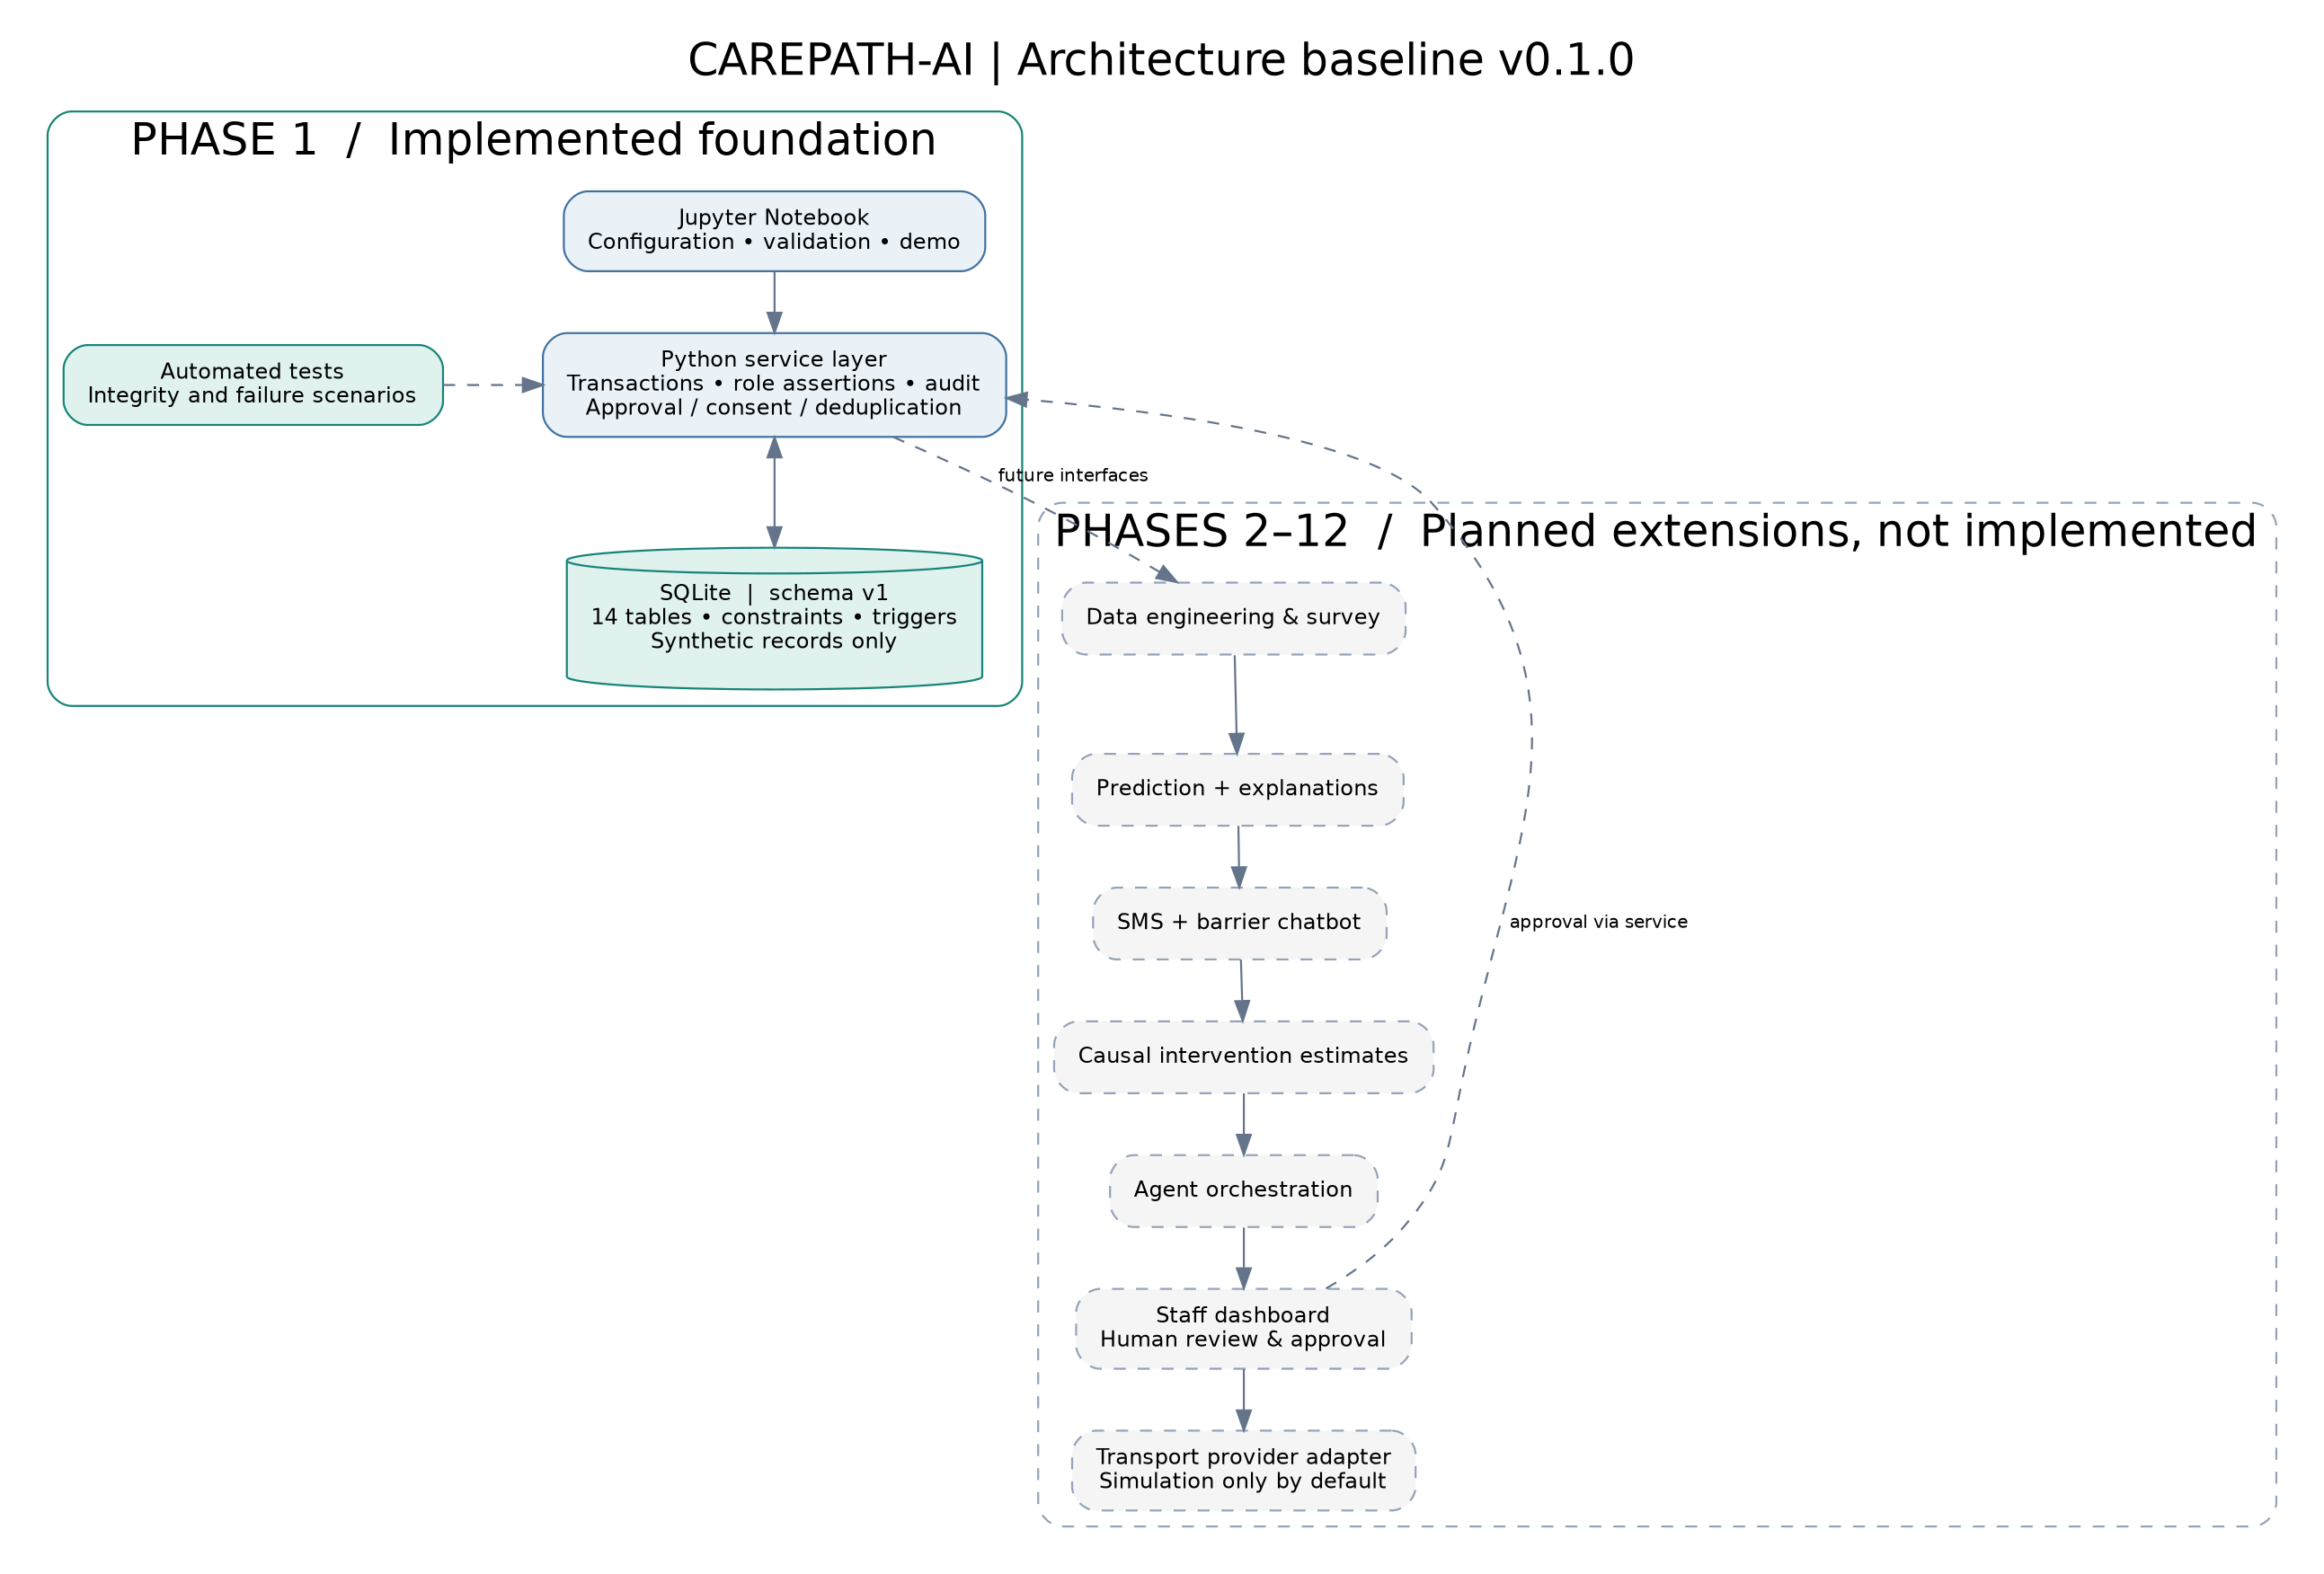

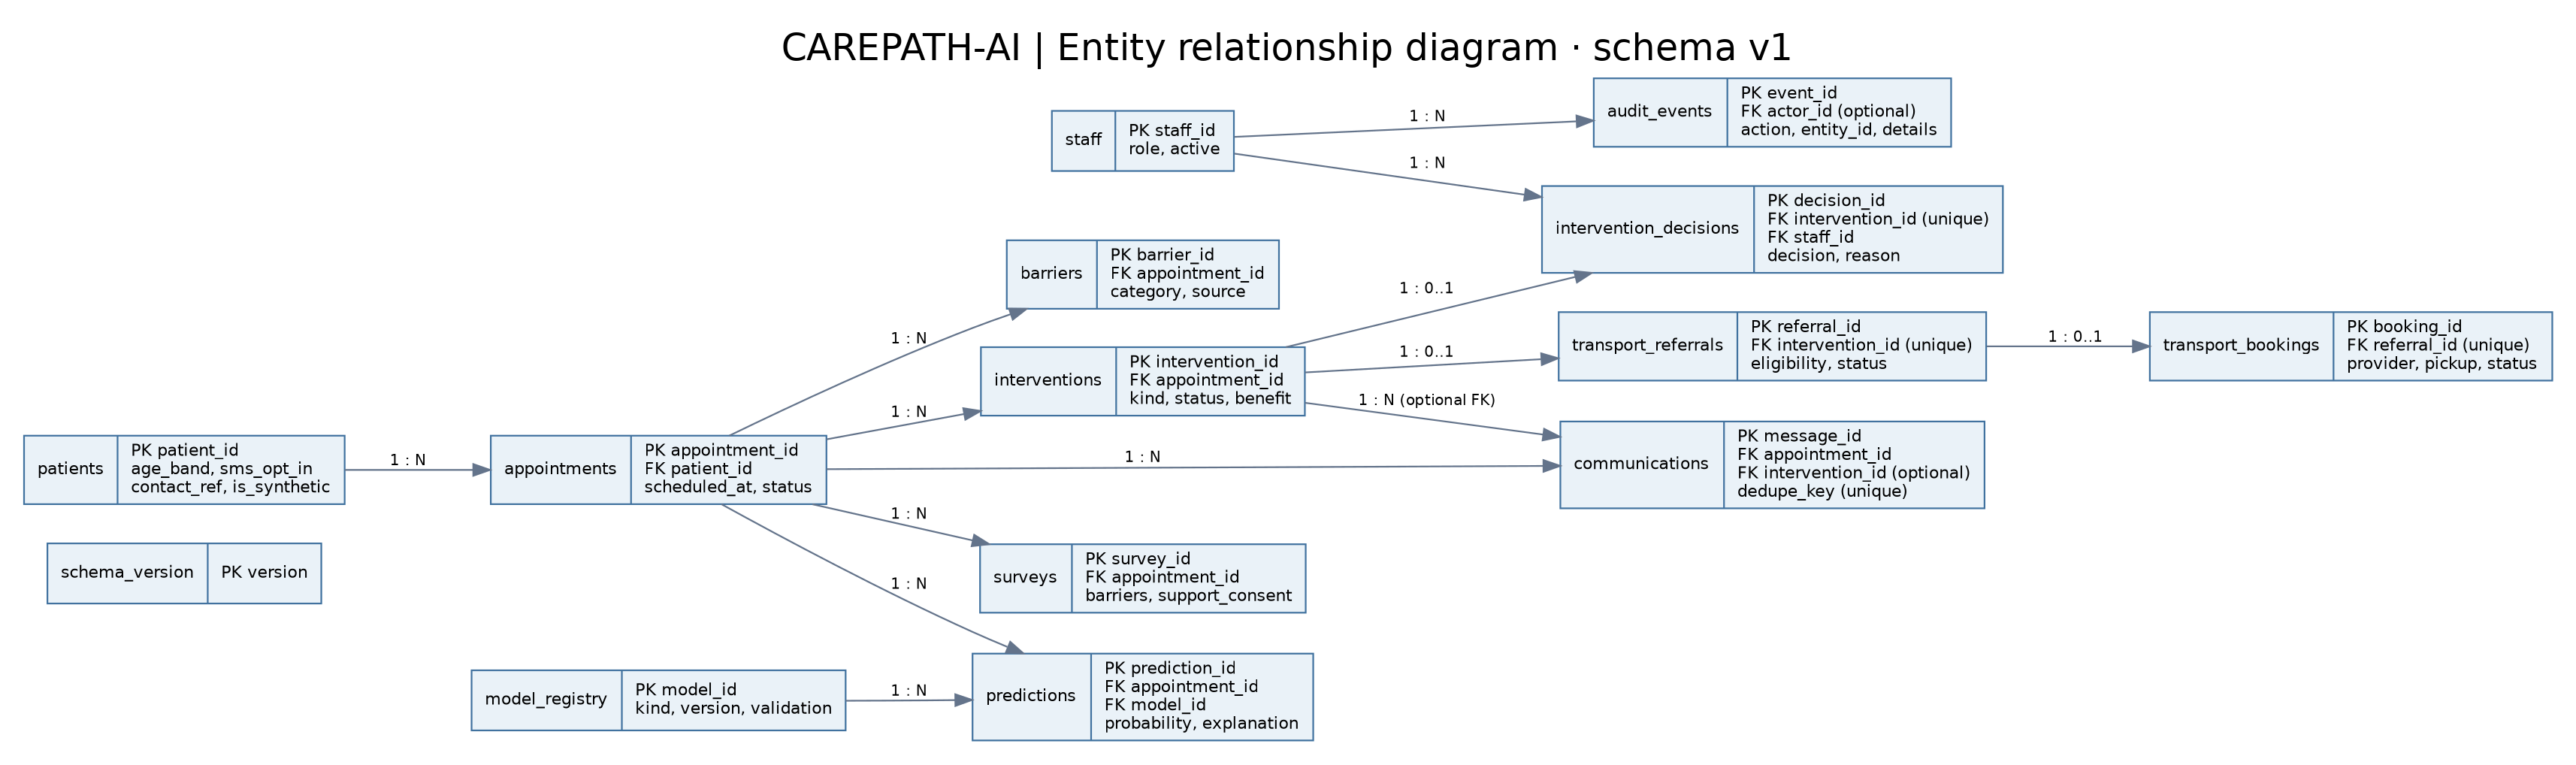

appointments              appointment_id, patient_id, scheduled_at, department, appointment_type, status, created_at
audit_events              event_id, actor_id, action, entity_type, entity_id, details_json, created_at
barriers                  barrier_id, appointment_id, category, source, recorded_at, confirmed
communications            message_id, appointment_id, intervention_id, channel, template_key, dedupe_key, status, created_at
intervention_decisions    decision_id, intervention_id, staff_id, decision, reason, decided_at
interventions             intervention_id, appointment_id, kind, rationale, estimated_benefit, evidence_status, status, created_at
model_registry            model_id, model_kind, version, artifact_path, validation_status
patients                  patient_id, age_band, contact_ref, sms_opt_in, is_synthetic, created_at
predictions               prediction_id, appointment_id, model_id, predicted_at, no_show_probability, explanation_json, is_simulated
schema_versio

In [ ]:
from IPython.display import Image

for diagram in ['architecture.png', 'erd.png']:
    file = ROOT/'documentation'/diagram
    if file.exists():
        display(Image(filename=str(file), width=900))
with connect(DB) as conn:
    tables = [row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name")]
    for name in tables:
        columns = [row['name'] for row in conn.execute(f'PRAGMA table_info("{name}")')]
        print(f'{name:25} {", ".join(columns)}')

## 4. Initialise synthetic demonstration records
The fixture contains three fictional patients with scheduled appointments and survey data. One approved transport intervention progresses to simulated booking and notification; a second intervention is rejected. The seed is idempotent and is not a training dataset.

In [7]:
with connect(DB) as conn:
    inserted = seed_demo(conn)
    snapshot = counts(conn)
    print('Fixture created:' if inserted else 'Fixture already present:', snapshot)
    print('Seed repeated:', seed_demo(conn))
    assert counts(conn) == snapshot

Fixture already present: {'staff': 4, 'patients': 3, 'appointments': 3, 'surveys': 3, 'model_registry': 1, 'predictions': 3, 'barriers': 3, 'interventions': 2, 'intervention_decisions': 2, 'communications': 2, 'transport_referrals': 1, 'transport_bookings': 1, 'audit_events': 9}
Seed repeated: False


## 5. Inspect patient journey
All values are stored in SQLite. The illustrative probabilities show the intended integration point for Phase 3. The demo shows simulated communications and booking, never an actual referral.

In [8]:
def show_query(sql, params=()):
    with connect(DB) as conn:
        cursor = conn.execute(sql, params)
        rows = cursor.fetchall()
        names = [col[0] for col in cursor.description]
    def esc(v): return str(v if v is not None else '—').replace('|', '\|').replace('\n',' ')
    display(Markdown('| ' + ' | '.join(names) + ' |\n|' + '|'.join(['---']*len(names)) + '|\n' + '\n'.join('| ' + ' | '.join(esc(v) for v in row) + ' |' for row in rows)))

show_query('SELECT appointment_id,patient_id,department,status,latest_risk FROM appointment_overview ORDER BY appointment_id')
show_query('SELECT i.intervention_id,i.kind,i.status,d.decision,d.staff_id FROM interventions i LEFT JOIN intervention_decisions d USING(intervention_id) ORDER BY i.intervention_id')
show_query('SELECT r.referral_id,r.eligibility_status,r.status AS referral_status,b.provider,b.pickup_at,b.status AS booking_status FROM transport_referrals r LEFT JOIN transport_bookings b USING(referral_id)')
show_query('SELECT message_id,appointment_id,template_key,status FROM communications ORDER BY message_id')
show_query('SELECT event_id,actor_id,action,entity_type,entity_id FROM audit_events ORDER BY event_id')

<>:6: SyntaxWarning: invalid escape sequence '\|'
<>:6: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_1243/3212042093.py:6: SyntaxWarning: invalid escape sequence '\|'
  def esc(v): return str(v if v is not None else '—').replace('|', '\|').replace('\n',' ')


| appointment_id | patient_id | department | status | latest_risk |
|---|---|---|---|---|
| A-001 | P-001 | Outpatients | scheduled | 0.82 |
| A-002 | P-002 | Physiotherapy | scheduled | 0.15 |
| A-003 | P-003 | Outpatients | scheduled | 0.61 |

| intervention_id | kind | status | decision | staff_id |
|---|---|---|---|---|
| I-001 | transport | in_progress | approve | S-REVIEW |
| I-002 | reschedule | rejected | reject | S-REVIEW |

| referral_id | eligibility_status | referral_status | provider | pickup_at | booking_status |
|---|---|---|---|---|---|
| R-001 | demo_eligible | submitted | SIMULATED_PROVIDER | 2027-01-15T09:00:00Z | simulated |

| message_id | appointment_id | template_key | status |
|---|---|---|---|
| MSG-001 | A-001 | support_invitation | simulated |
| MSG-002 | A-001 | transport_confirmation | simulated |

| event_id | actor_id | action | entity_type | entity_id |
|---|---|---|---|---|
| 1 | S-COORD | proposed | intervention | I-001 |
| 2 | S-COORD | sms_simulated | communication | MSG-001 |
| 3 | S-REVIEW | approve | intervention | I-001 |
| 4 | S-COORD | referral_created | transport_referral | R-001 |
| 5 | S-COORD | booking_simulated | transport_booking | BK-001 |
| 6 | S-COORD | sms_simulated | communication | MSG-002 |
| 7 | S-COORD | proposed | intervention | I-002 |
| 8 | S-REVIEW | reject | intervention | I-002 |
| 9 | S-ADMIN | demo_seeded | fixture | phase1 |

## 6. Database integrity and test execution
Tests create isolated temporary databases. They cover valid workflows, negative cases, role restrictions, consent, duplicate prevention, immutable records, rollback, foreign keys and schema versioning. No tests modify the supplied demo database.

In [ ]:
with connect(DB) as conn:
    checks = integrity(conn)
    table_counts = counts(conn)
print(json.dumps(checks, indent=2))
assert checks['integrity_check'] == 'ok'
assert not checks['foreign_key_violations']
assert checks['table_count'] == 14
assert checks['schema_version'] == 1

# Use this notebook's Python interpreter, with explicit Unicode handling.
import re
reports = ROOT / 'reports'
reports.mkdir(exist_ok=True)
result = subprocess.run(
    [sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
    cwd=str(ROOT), env={**os.environ, 'PYTHONIOENCODING': 'utf-8'},
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    encoding='utf-8', errors='replace', check=False,
)
test_log = result.stdout
log_path = reports / 'test_results.txt'
log_path.write_text(test_log, encoding='utf-8')
print(test_log)
print('Test log saved to:', log_path)
match = re.search(r'Ran (\d+) tests?', test_log)
if result.returncode != 0 or not match or int(match.group(1)) != 28:
    # Do not leave a stale PASS report when a later run fails.
    (reports / 'validation_report.json').write_text(json.dumps({
        'project': 'CarePath-AI', 'phase': 1, 'version': '0.1.1',
        'acceptance': 'FAIL', 'test_exit_code': result.returncode,
        'database_integrity': checks, 'test_log': str(log_path)
    }, indent=2), encoding='utf-8')
    raise AssertionError(f'Foundation tests failed or incomplete (exit {result.returncode}). See the output above and {log_path}.')
print('Foundation validations completed successfully.')

{
  "integrity_check": "ok",
  "foreign_key_violations": [],
  "schema_version": 1,
  "table_count": 14
}


test_analyst_write_denied (test_foundation.FoundationTests.test_analyst_write_denied) ... Database transaction rolled back: PermissionError
ok
test_audit_immutable (test_foundation.FoundationTests.test_audit_immutable) ... Database transaction rolled back: IntegrityError
Database transaction rolled back: IntegrityError
ok
test_cancelled_appointment_sms_blocked (test_foundation.FoundationTests.test_cancelled_appointment_sms_blocked) ... Database transaction rolled back: IntegrityError
ok
test_config_offline (test_foundation.FoundationTests.test_config_offline) ... ok
test_confirmation_requires_approval (test_foundation.FoundationTests.test_confirmation_requires_approval) ... Database transaction rolled back: ValueError
ok
test_coordinator_cannot_approve (test_foundation.FoundationTests.test_coordinator_cannot_approve) ... Database transaction rolled back: PermissionError
Database transaction rolled back: IntegrityError
ok
test_cross_appointment_message (test_foundation.FoundationTests.t